# Severe wasting prediction: Stage 1 (initial fit)

**Scope of this notebook version:** Stage 1 only. XGBoost and CatBoost, split by `young`, two feature sets for `young = 1`, collinearity analysis, 5-fold CV with Optuna tuning, and the metrics AUC / F1 / precision / recall / confusion matrix.
Stage 2 (feature engineering) and Stage 3 (ensembling with RF, NN, etc.) are intentionally *not* here yet. This notebook saves its out-of-fold predictions and fold map so those stages can be compared on identical folds.

**Design decisions (from `PROJECT_CONTEXT.md`)**
- Data file is the **revised `.dta`** (22,311 rows, 80 vars). It is a Stata file, not a CSV.
- Target `severe_wasting` (WHZ < -3). `whz2`, `mod_wasting`, `any_wasting`, `wast_cat` and all IDs are **never** used as predictors.
- Three modelling datasets, fixed up front:

| Key | Rows | Features |
|---|---|---|
| `Y0_full` | `young = 0` (ages 2-4) | full-model variables |
| `Y1_full` | `young = 1` (ages 0-1) | full-model variables |
| `Y1_full+infant` | `young = 1` | full-model + infant-only variables |

- `young` itself is constant inside each split, so it is not fed to the models (it defines the split).
- CV: **outer 5-fold** `StratifiedGroupKFold` (grouped by PSU `hh1`, stratified on outcome) for evaluation; **inner 3-fold** on the outer-training part for **Optuna** tuning (nested, so test folds never influence tuning or the F1 threshold).
- Accuracy is not reported as a headline (97.5% from predicting all zeros). Because AUC is expected near 0.55-0.65, **F1 / precision will be low by construction**; read them together with AUC.

In [1]:
import os, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import optuna
from scipy.stats import chi2_contingency
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, confusion_matrix, roc_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ---------------- configuration ----------------
SEED      = 42
N_OUTER   = 5          # evaluation folds (as requested)
N_INNER   = 3          # folds used inside Optuna objective
QUICK     = os.environ.get('QUICK', '0') == '1'      # smoke-test switch
N_TRIALS  = 2 if QUICK else 30                        # Optuna trials per outer fold per model
EST_MAX   = 150 if QUICK else 600                     # max trees / iterations
THREADS   = max(1, (os.cpu_count() or 2) - 1)
OUT       = 'outputs'; os.makedirs(OUT, exist_ok=True)
PATH = r'C:\Users\Mahin\OneDrive\Desktop\MICS\MICS-child-ISRC-revised.dta'
if not os.path.exists(PATH): raise FileNotFoundError(f'Data file not found at {PATH}')
print('data:', PATH, '| QUICK =', QUICK, '| trials =', N_TRIALS, '| threads =', THREADS)

data: C:\Users\Mahin\OneDrive\Desktop\MICS\MICS-child-ISRC-revised.dta | QUICK = False | trials = 30 | threads = 11


In [2]:
FULL = ['age_m','female','division','urban','wb4','parity_cat','diarrhoea_2w','cough_2w','breathing_2w',
        'has_mother','fuel_cat','water_cat','toilet_cat','edu_level','birth_order','mother_age_at_birth',
        'water_treated','water_boil_filter','handwash_place','handwash_water','floor_quality']   # 'young' = split key
INFANT = ['bd9','dds','fvs','anc_cat','bf_status','bottle','birth_size','suppl_yday','early_bf']
# purely categorical (no order) -> one-hot for linear models, categorical for CatBoost
NOMINAL = ['division','fuel_cat','water_cat','toilet_cat','handwash_place','anc_cat','bf_status']
TARGET, GROUP, WEIGHT = 'severe_wasting', 'hh1', 'chweight'
FORBIDDEN = {'whz2','mod_wasting','any_wasting','wast_cat','hh2','ln','child_id','mother_id','hh_id'}
assert not (set(FULL+INFANT) & FORBIDDEN), 'leakage / ID variable in feature list'

df = pd.read_stata(PATH, convert_categoricals=False).reset_index(drop=True)
assert df.shape[0] == 22311 and df[TARGET].sum() == 552
print(df.groupby('young')[TARGET].agg(n='size', cases='sum', prev='mean').round(4))

na = pd.DataFrame({'NA% young=0': df.loc[df.young==0, FULL+INFANT].isna().mean(),
                   'NA% young=1': df.loc[df.young==1, FULL+INFANT].isna().mean()}).round(3)
na.T

           n  cases    prev
young                      
0      13423    255  0.0190
1       8888    297  0.0334


,age_m,female,division,urban,wb4,parity_cat,diarrhoea_2w,cough_2w,breathing_2w,has_mother,...,floor_quality,bd9,dds,fvs,anc_cat,bf_status,bottle,birth_size,suppl_yday,early_bf
NA% young=0,0.0,0.0,0.0,0.0,0.017,0.017,0.001,0.000,0.0,0.0,...,0.004,1.000,1.000,1.00,1.00,1.0,1.0,0.986,1.000,0.986
NA% young=1,0.0,0.0,0.0,0.0,0.004,0.004,0.000,0.001,0.0,0.0,...,0.003,0.266,0.008,0.01,0.01,0.0,0.0,0.034,0.001,0.041


## 1. Association / collinearity analysis (label-free)

The predictors are strongly related (mother's age, parity, birth order, age at birth; `dds` vs `fvs`; water / sanitation / fuel). Before modelling we:
1. compute a **mixed association matrix**: |Spearman| for ordinal/binary/numeric pairs, bias-corrected **Cramér's V** whenever a nominal variable is involved (continuous vars are quintile-binned for that);
2. compute **VIF** (nominal variables one-hot encoded);
3. **prune** one member of every pair with association >= 0.70, dropping the variable with more missingness, then the one more redundant overall. `age_m` and `female` are protected.

This uses **no outcome information**, so it cannot leak and may be done once outside the CV loop. Infant-only variables are pruned after the full-model set, and the full-model variables kept for `Y1_full` are protected, so the two `young = 1` sets are properly nested (infant set = full set + extra variables).

In [3]:
def cramers_v(a, b):
    t = pd.crosstab(a, b)
    if t.shape[0] < 2 or t.shape[1] < 2: return 0.0
    n = t.values.sum(); chi2 = chi2_contingency(t, correction=False)[0]
    r, k = t.shape; phi2 = max(0, chi2/n - (k-1)*(r-1)/(n-1))
    rc, kc = r - (r-1)**2/(n-1), k - (k-1)**2/(n-1)
    d = min(kc-1, rc-1)
    return float(np.sqrt(phi2/d)) if d > 0 else 0.0

def binned(s):
    return pd.qcut(s, 5, duplicates='drop') if s.nunique() > 10 else s

def assoc_matrix(d, cols):
    M = pd.DataFrame(np.eye(len(cols)), index=cols, columns=cols)
    for i, a in enumerate(cols):
        for b in cols[i+1:]:
            pair = d[[a, b]].dropna()
            if len(pair) < 50 or pair[a].nunique() < 2 or pair[b].nunique() < 2: v = 0.0
            elif a in NOMINAL or b in NOMINAL:
                v = cramers_v(binned(pair[a]), binned(pair[b]))
            else:
                v = abs(pair[a].corr(pair[b], method='spearman'))
            M.loc[a, b] = M.loc[b, a] = v
    return M

def vif_table(d, cols):
    X = d[cols].copy()
    X = X.fillna(X.median())
    X = pd.get_dummies(X, columns=[c for c in cols if c in NOMINAL], drop_first=True, dtype=float)
    X = X.loc[:, X.std() > 0]
    R = np.corrcoef(X.values, rowvar=False)
    v = np.diag(np.linalg.pinv(R))
    return pd.Series(v, index=X.columns).sort_values(ascending=False)

def prune(d, cols, protected, thr=0.70):
    cols = [c for c in cols if d[c].nunique() > 1]           # drop constants
    M = assoc_matrix(d, cols); keep = list(cols); log = []
    while True:
        sub = M.loc[keep, keep].values.copy(); np.fill_diagonal(sub, 0)
        i, j = np.unravel_index(sub.argmax(), sub.shape)
        if sub[i, j] < thr: break
        a, b = keep[i], keep[j]
        cand = [c for c in (a, b) if c not in protected]
        if not cand:  # both protected: cannot drop, stop checking this pair
            M.loc[a, b] = M.loc[b, a] = 0; continue
        miss = {c: d[c].isna().mean() for c in cand}
        red  = {c: M.loc[c, [k for k in keep if k != c]].mean() for c in cand}
        drop = max(cand, key=lambda c: (round(miss[c], 3), red[c]))
        log.append((a, b, round(sub[i, j], 3), drop)); keep.remove(drop)
    return keep, M, pd.DataFrame(log, columns=['var_A','var_B','assoc','dropped'])

d0, d1 = df[df.young == 0], df[df.young == 1]
PROT = {'age_m', 'female'}

keep0, M0, log0 = prune(d0, FULL, PROT)
keep1, M1, log1 = prune(d1, FULL, PROT)
keep1i, M1i, log1i = prune(d1, keep1 + INFANT, PROT | set(keep1))   # full-model survivors protected

print('== young=0, full set: pairs >= 0.70 and what was dropped'); display(log0) if len(log0) else print('none')
print('== young=1, full set'); display(log1) if len(log1) else print('none')
print('== young=1, infant additions (full survivors protected)'); display(log1i) if len(log1i) else print('none')

top = lambda M, n=8: (M.where(np.triu(np.ones(M.shape), 1).astype(bool)).stack().sort_values(ascending=False).head(n).round(3))
print('\nStrongest raw associations, young=1 (full + infant):'); display(top(assoc_matrix(d1, FULL+INFANT), 12))

== young=0, full set: pairs >= 0.70 and what was dropped


,var_A,var_B,assoc,dropped
0,water_treated,water_boil_filter,0.864,water_boil_filter
1,parity_cat,birth_order,0.831,birth_order
2,wb4,mother_age_at_birth,0.784,mother_age_at_birth
3,handwash_place,handwash_water,0.769,handwash_place


== young=1, full set


,var_A,var_B,assoc,dropped
0,parity_cat,birth_order,0.930,birth_order
1,water_treated,water_boil_filter,0.884,water_boil_filter
2,wb4,mother_age_at_birth,0.789,mother_age_at_birth
3,handwash_place,handwash_water,0.773,handwash_water
4,wb4,parity_cat,0.708,parity_cat


== young=1, infant additions (full survivors protected)


,var_A,var_B,assoc,dropped
0,dds,fvs,0.972,fvs



Strongest raw associations, young=1 (full + infant):


dds             fvs                    0.972
parity_cat      birth_order            0.930
water_treated   water_boil_filter      0.884
wb4             mother_age_at_birth    0.789
handwash_place  handwash_water         0.773
wb4             parity_cat             0.708
                birth_order            0.666
age_m           fvs                    0.636
                dds                    0.631
parity_cat      mother_age_at_birth    0.573
birth_order     mother_age_at_birth    0.572
cough_2w        breathing_2w           0.497
dtype: float64

Highest VIF before pruning (young=1, all vars):


dds                   11.90
fvs                   11.26
handwash_place_2.0     7.57
parity_cat             7.20
birth_order            6.38
handwash_place_1.0     5.95
water_treated          4.90
water_boil_filter      4.89
dtype: float64

Highest VIF after pruning:


anc_cat_2.0           4.22
anc_cat_1.0           3.90
bf_status_2.0         3.77
bf_status_1.0         3.69
division_2            3.48
division_3            3.48
handwash_place_2.0    3.19
handwash_place_1.0    2.98
dtype: float64

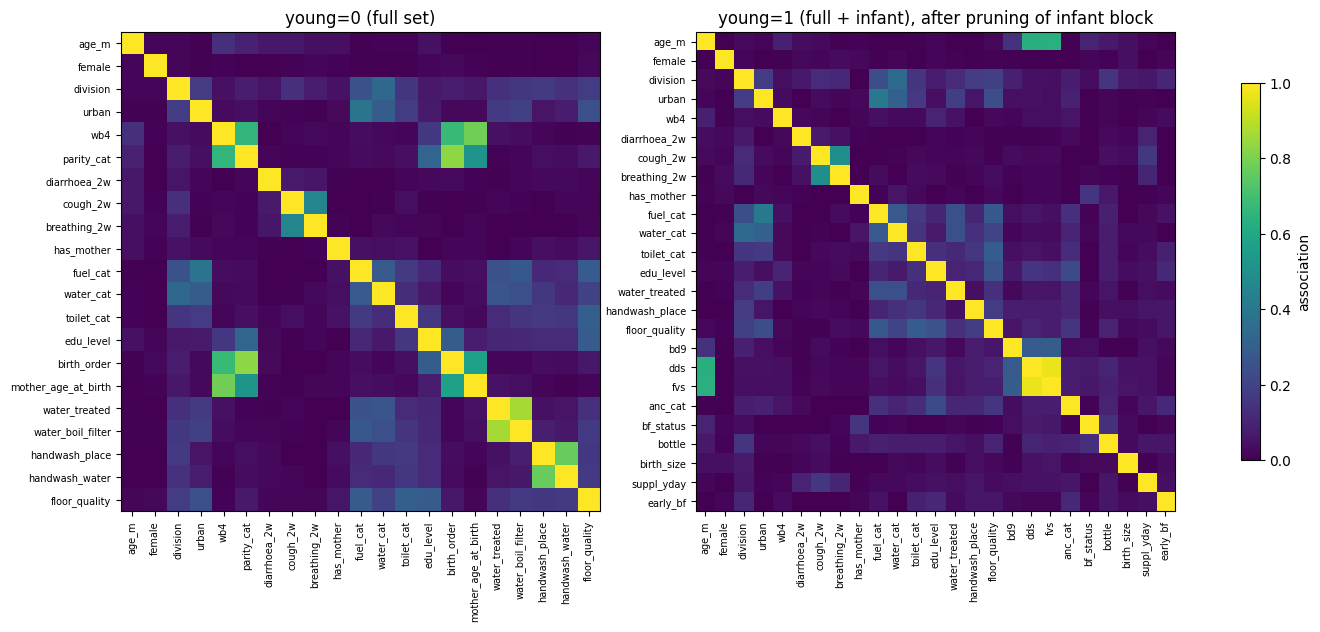

Y0_full         n= 13423 cases= 255  p=17  EPV= 15.0
    ['age_m', 'female', 'division', 'urban', 'wb4', 'parity_cat', 'diarrhoea_2w', 'cough_2w', 'breathing_2w', 'has_mother', 'fuel_cat', 'water_cat', 'toilet_cat', 'edu_level', 'water_treated', 'handwash_water', 'floor_quality']
Y1_full         n=  8888 cases= 297  p=16  EPV= 18.6
    ['age_m', 'female', 'division', 'urban', 'wb4', 'diarrhoea_2w', 'cough_2w', 'breathing_2w', 'has_mother', 'fuel_cat', 'water_cat', 'toilet_cat', 'edu_level', 'water_treated', 'handwash_place', 'floor_quality']
Y1_full+infant  n=  8888 cases= 297  p=24  EPV= 12.4
    ['age_m', 'female', 'division', 'urban', 'wb4', 'diarrhoea_2w', 'cough_2w', 'breathing_2w', 'has_mother', 'fuel_cat', 'water_cat', 'toilet_cat', 'edu_level', 'water_treated', 'handwash_place', 'floor_quality', 'bd9', 'dds', 'anc_cat', 'bf_status', 'bottle', 'birth_size', 'suppl_yday', 'early_bf']


In [4]:
before = vif_table(d1, FULL+INFANT); after = vif_table(d1, keep1i)
print('Highest VIF before pruning (young=1, all vars):'); display(before.head(8).round(2))
print('Highest VIF after pruning:');                      display(after.head(8).round(2))

fig, ax = plt.subplots(1, 2, figsize=(17, 7))
for a, M, t in [(ax[0], M0, 'young=0 (full set)'), (ax[1], M1i, 'young=1 (full + infant), after pruning of infant block')]:
    im = a.imshow(M.values, vmin=0, vmax=1, cmap='viridis'); a.set_title(t)
    a.set_xticks(range(len(M))); a.set_xticklabels(M.columns, rotation=90, fontsize=7)
    a.set_yticks(range(len(M))); a.set_yticklabels(M.index, fontsize=7)
plt.colorbar(im, ax=ax, shrink=.7, label='association'); plt.show()

DATASETS = {
    'Y0_full':        (d0.reset_index(drop=True), keep0),
    'Y1_full':        (d1.reset_index(drop=True), keep1),
    'Y1_full+infant': (d1.reset_index(drop=True), keep1i),
}
for k, (d, f) in DATASETS.items():
    print(f'{k:15s} n={len(d):6d} cases={int(d[TARGET].sum()):4d}  p={len(f):2d}  EPV={d[TARGET].sum()/len(f):5.1f}')
    print('   ', f)
json.dump({k: v[1] for k, v in DATASETS.items()}, open(f'{OUT}/feature_sets.json', 'w'), indent=1)

## 2. Fixed folds (reproducible)

Folds are created **once per `young` group** and saved to `outputs/fold_assignment.csv`. `Y1_full` and `Y1_full+infant` use the *same rows and same folds*, so their difference is a paired comparison. The same fold map will be reused in Stage 2/3.

In [5]:
def make_folds(d, seed=SEED):
    fold = np.full(len(d), -1)
    sgkf = StratifiedGroupKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)
    for k, (_, te) in enumerate(sgkf.split(d, d[TARGET], d[GROUP])): fold[te] = k
    return fold

FOLDS = {'Y0_full': make_folds(DATASETS['Y0_full'][0])}
FOLDS['Y1_full'] = FOLDS['Y1_full+infant'] = make_folds(DATASETS['Y1_full'][0])

chk = []
for k, (d, f) in DATASETS.items():
    for i in range(N_OUTER):
        m = FOLDS[k] == i
        chk.append(dict(dataset=k, fold=i, n=int(m.sum()), cases=int(d.loc[m, TARGET].sum()), PSUs=d.loc[m, GROUP].nunique()))
    assert d.groupby(GROUP).apply(lambda g: FOLDS[k][g.index].min() == FOLDS[k][g.index].max()).all()  # no PSU split across folds
display(pd.DataFrame(chk).pivot(index='fold', columns='dataset', values='cases').rename_axis(None).T.assign(note='cases per fold'))

fa = pd.concat([pd.DataFrame({'dataset': k, 'row_in_group': np.arange(len(d)), 'child_id': d['child_id'] if 'child_id' in d else np.arange(len(d)),
                              'hh1': d[GROUP], 'fold': FOLDS[k]}) for k, (d, f) in DATASETS.items()])
fa.to_csv(f'{OUT}/fold_assignment.csv', index=False)

,0,1,2,3,4,note
dataset,,,,,,
Y0_full,53,47,49,47,59,cases per fold
Y1_full,55,56,56,72,58,cases per fold
Y1_full+infant,55,56,56,72,58,cases per fold


## 3. Models, Optuna search spaces and metrics

- **XGBoost**: native NaN handling, nominal variables as integer codes.
- **CatBoost**: native NaN handling, nominal variables passed as true categorical features.
- Class imbalance (~40:1) handled by `scale_pos_weight`, which is itself an Optuna hyper-parameter (1 to the full imbalance ratio).
- Optuna objective = mean AUC over the 3 inner folds (TPE sampler, median pruner). The best trial's inner out-of-fold scores are used to choose the **F1-maximising threshold**, so the outer test fold is never used for any choice.
- Reported metrics come from the outer test folds only: pooled out-of-fold AUC, per-fold AUC (mean ± SD), survey-weighted AUC, PR-AUC, top-decile capture, and precision / recall / F1 / confusion matrix at the inner-selected thresholds.

In [6]:
def to_cb(X):
    X = X.copy()
    for c in NOMINAL:
        if c in X: X[c] = X[c].map(lambda v: 'NA' if pd.isna(v) else str(int(v)))
    return X

def suggest(trial, name, ratio):
    if name == 'XGBoost':
        return dict(n_estimators=trial.suggest_int('n_estimators', 100, EST_MAX),
                    learning_rate=trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
                    max_depth=trial.suggest_int('max_depth', 2, 6),
                    min_child_weight=trial.suggest_float('min_child_weight', 1, 30, log=True),
                    subsample=trial.suggest_float('subsample', 0.5, 1.0),
                    colsample_bytree=trial.suggest_float('colsample_bytree', 0.4, 1.0),
                    reg_lambda=trial.suggest_float('reg_lambda', 1e-2, 50, log=True),
                    reg_alpha=trial.suggest_float('reg_alpha', 1e-3, 5, log=True),
                    gamma=trial.suggest_float('gamma', 0, 5),
                    scale_pos_weight=trial.suggest_float('scale_pos_weight', 1, ratio, log=True))
    return dict(iterations=trial.suggest_int('iterations', 100, EST_MAX),
                learning_rate=trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
                depth=trial.suggest_int('depth', 3, 6),
                l2_leaf_reg=trial.suggest_float('l2_leaf_reg', 1, 50, log=True),
                random_strength=trial.suggest_float('random_strength', 0.1, 5, log=True),
                bagging_temperature=trial.suggest_float('bagging_temperature', 0, 3),
                scale_pos_weight=trial.suggest_float('scale_pos_weight', 1, ratio, log=True))

def build(name, params, cols, seed):
    if name == 'XGBoost':
        return XGBClassifier(**params, tree_method='hist', n_jobs=THREADS, random_state=seed, verbosity=0)
    return CatBoostClassifier(**params, cat_features=[c for c in cols if c in NOMINAL], random_seed=seed,
                              verbose=0, thread_count=THREADS, allow_writing_files=False)

def prep(name, X): return to_cb(X) if name == 'CatBoost' else X.astype('float32')

def best_f1_threshold(y, p):
    ts = np.unique(np.quantile(p, np.linspace(0.50, 0.999, 250)))
    f = [f1_score(y, p >= t, zero_division=0) for t in ts]
    return float(ts[int(np.argmax(f))])

def tune_and_fit(name, X, y, g, k, cols):
    """Optuna on (X, y) = outer-train; returns fitted model, threshold, best params, best inner AUC."""
    ratio = float((1 - y.mean()) / y.mean()); store = {}
    inner = list(StratifiedGroupKFold(N_INNER, shuffle=True, random_state=SEED + k).split(X, y, g))
    Xp = prep(name, X)
    def objective(trial):
        params = suggest(trial, name, ratio); oof = np.full(len(y), np.nan); aucs = []
        for i, (a, b) in enumerate(inner):
            m = build(name, params, cols, SEED).fit(Xp.iloc[a], y[a])
            oof[b] = m.predict_proba(Xp.iloc[b])[:, 1]; aucs.append(roc_auc_score(y[b], oof[b]))
            trial.report(float(np.mean(aucs)), i)
            if trial.should_prune(): raise optuna.TrialPruned()
        store[trial.number] = oof
        return float(np.mean(aucs))
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED + k),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1))
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)
    bt = study.best_trial; thr = best_f1_threshold(y, store[bt.number])
    model = build(name, bt.params, cols, SEED).fit(Xp, y)
    return model, thr, bt.params, bt.value

def importances(model, name, cols):
    v = model.feature_importances_ if name == 'XGBoost' else model.get_feature_importance()
    return pd.Series(np.asarray(v, float) / np.sum(v), index=cols)

def summarise(y, p, pred, w, fold):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    top = p >= np.quantile(p, 0.9)
    fa = [roc_auc_score(y[fold == i], p[fold == i]) for i in np.unique(fold)]
    return dict(AUC=roc_auc_score(y, p), AUC_fold_mean=np.mean(fa), AUC_fold_sd=np.std(fa, ddof=1),
                AUC_weighted=roc_auc_score(y, p, sample_weight=w), PR_AUC=average_precision_score(y, p),
                top10_capture=y[top].sum() / y.sum(), Precision=precision_score(y, pred, zero_division=0),
                Recall=recall_score(y, pred), F1=f1_score(y, pred), TN=tn, FP=fp, FN=fn, TP=tp)

In [7]:
RESULTS, IMPORTANCE, BEST = {}, {}, {}
LOG_T0 = time.time()

for key, (d, cols) in DATASETS.items():
    X, y, g, w, fold = d[cols], d[TARGET].values.astype(int), d[GROUP].values, d[WEIGHT].values, FOLDS[key]
    # ---- benchmark: age + sex logistic (same folds, threshold from training predictions) ----
    p = np.zeros(len(d)); pred = np.zeros(len(d), int)
    for k in range(N_OUTER):
        tr, te = np.where(fold != k)[0], np.where(fold == k)[0]
        lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(d.loc[tr, ['age_m','female']], y[tr])
        thr = best_f1_threshold(y[tr], lr.predict_proba(d.loc[tr, ['age_m','female']])[:, 1])
        p[te] = lr.predict_proba(d.loc[te, ['age_m','female']])[:, 1]; pred[te] = p[te] >= thr
    RESULTS[(key, 'Benchmark age+sex')] = dict(p=p, pred=pred, summary=summarise(y, p, pred, w, fold))

    for name in ['XGBoost', 'CatBoost']:
        p = np.zeros(len(d)); pred = np.zeros(len(d), int); imps = []; bests = []
        for k in range(N_OUTER):
            tr, te = np.where(fold != k)[0], np.where(fold == k)[0]
            model, thr, params, inner_auc = tune_and_fit(name, X.iloc[tr].reset_index(drop=True), y[tr], g[tr], k, cols)
            p[te] = model.predict_proba(prep(name, X.iloc[te]))[:, 1]; pred[te] = p[te] >= thr
            imps.append(importances(model, name, cols))
            bests.append(dict(fold=k, inner_auc=inner_auc, threshold=thr, test_auc=roc_auc_score(y[te], p[te]), **params))
            print(f'[{(time.time()-LOG_T0)/60:5.1f} min] {key:15s} {name:8s} fold {k}: inner AUC {inner_auc:.3f} -> test AUC {bests[-1]["test_auc"]:.3f}')
        RESULTS[(key, name)] = dict(p=p, pred=pred, summary=summarise(y, p, pred, w, fold))
        IMPORTANCE[(key, name)] = pd.concat(imps, axis=1).mean(axis=1).sort_values(ascending=False)
        BEST[(key, name)] = pd.DataFrame(bests)
        pd.DataFrame({'row_in_group': np.arange(len(d)), 'fold': fold, 'y': y, 'p': p, 'pred': pred}).to_csv(f'{OUT}/oof_{key}_{name}.csv', index=False)

table = pd.DataFrame({k: v['summary'] for k, v in RESULTS.items()}).T
table.index.names = ['dataset', 'model']
table.to_csv(f'{OUT}/stage1_results.csv')
pd.concat(BEST, names=['dataset', 'model', 'i']).to_csv(f'{OUT}/stage1_best_params.csv')

[  0.2 min] Y0_full         XGBoost  fold 0: inner AUC 0.522 -> test AUC 0.446
[  0.4 min] Y0_full         XGBoost  fold 1: inner AUC 0.530 -> test AUC 0.543
[  0.6 min] Y0_full         XGBoost  fold 2: inner AUC 0.528 -> test AUC 0.470
[  0.7 min] Y0_full         XGBoost  fold 3: inner AUC 0.528 -> test AUC 0.562
[  0.9 min] Y0_full         XGBoost  fold 4: inner AUC 0.570 -> test AUC 0.481
[ 12.8 min] Y0_full         CatBoost fold 0: inner AUC 0.517 -> test AUC 0.469
[ 22.3 min] Y0_full         CatBoost fold 1: inner AUC 0.537 -> test AUC 0.564
[ 27.4 min] Y0_full         CatBoost fold 2: inner AUC 0.538 -> test AUC 0.546
[ 33.1 min] Y0_full         CatBoost fold 3: inner AUC 0.525 -> test AUC 0.594
[ 39.2 min] Y0_full         CatBoost fold 4: inner AUC 0.586 -> test AUC 0.479
[ 39.3 min] Y1_full         XGBoost  fold 0: inner AUC 0.581 -> test AUC 0.582
[ 39.5 min] Y1_full         XGBoost  fold 1: inner AUC 0.596 -> test AUC 0.578
[ 39.6 min] Y1_full         XGBoost  fold 2: inner A

## 4. Results

In [8]:
show = table.copy()
for c in ['AUC','AUC_fold_mean','AUC_fold_sd','AUC_weighted','PR_AUC','top10_capture','Precision','Recall','F1']: show[c] = show[c].astype(float).round(3)
for c in ['TN','FP','FN','TP']: show[c] = show[c].astype(int)
display(show)

AUC  AUC_fold_mean  AUC_fold_sd  \
dataset        model                                                  
Y0_full        Benchmark age+sex  0.512          0.539        0.062   
               XGBoost            0.507          0.500        0.050   
               CatBoost           0.512          0.530        0.054   
Y1_full        Benchmark age+sex  0.570          0.575        0.028   
               XGBoost            0.532          0.570        0.014   
               CatBoost           0.536          0.583        0.024   
Y1_full+infant Benchmark age+sex  0.570          0.575        0.028   
               XGBoost            0.525          0.591        0.031   
               CatBoost           0.558          0.583        0.026   

                                  AUC_weighted  PR_AUC  top10_capture  \
dataset        model                                                    
Y0_full        Benchmark age+sex         0.523   0.020          0.106   
               XGBoost                   0.498   0.019          0.078   
               CatBoost                  0.508   0.020          0.114   
Y1_full        Benchmark age+sex         0.566   0.052          0.205   
               XGBoost                   0.531   0.042          0.141   
               CatBoost                  0.527   0.037          0.098   
Y1_full+infant Benchmark age+sex         0.566   0.052          0.205   
               XGBoost                   0.535   0.046          0.135   
               CatBoost                  0.557   0.041          0.145   

                                  Precision  Recall     F1     TN    FP   FN  \
dataset        model                                                           
Y0_full        Benchmark age+sex      0.025   0.267  0.045  10474  2694  187   
               XGBoost                0.019   0.325  0.036   8922  4246  172   
               CatBoost               0.025   0.184  0.043  11306  1862  208   
Y1_full        Benchmark age+sex      0.078   0.145  0.101   8083   508  254   
               XGBoost                0.070   0.189  0.102   7845   746  241   
               CatBoost               0.059   0.242  0.095   7438  1153  225   
Y1_full+infant Benchmark age+sex      0.078   0.145  0.101   8083   508  254   
               XGBoost                0.070   0.168  0.099   7925   666  247   
               CatBoost               0.058   0.256  0.095   7356  1235  221   

                                  TP  
dataset        model                  
Y0_full        Benchmark age+sex  68  
               XGBoost            83  
               CatBoost           47  
Y1_full        Benchmark age+sex  43  
               XGBoost            56  
               CatBoost           72  
Y1_full+infant Benchmark age+sex  43  
               XGBoost            50  
               CatBoost           76

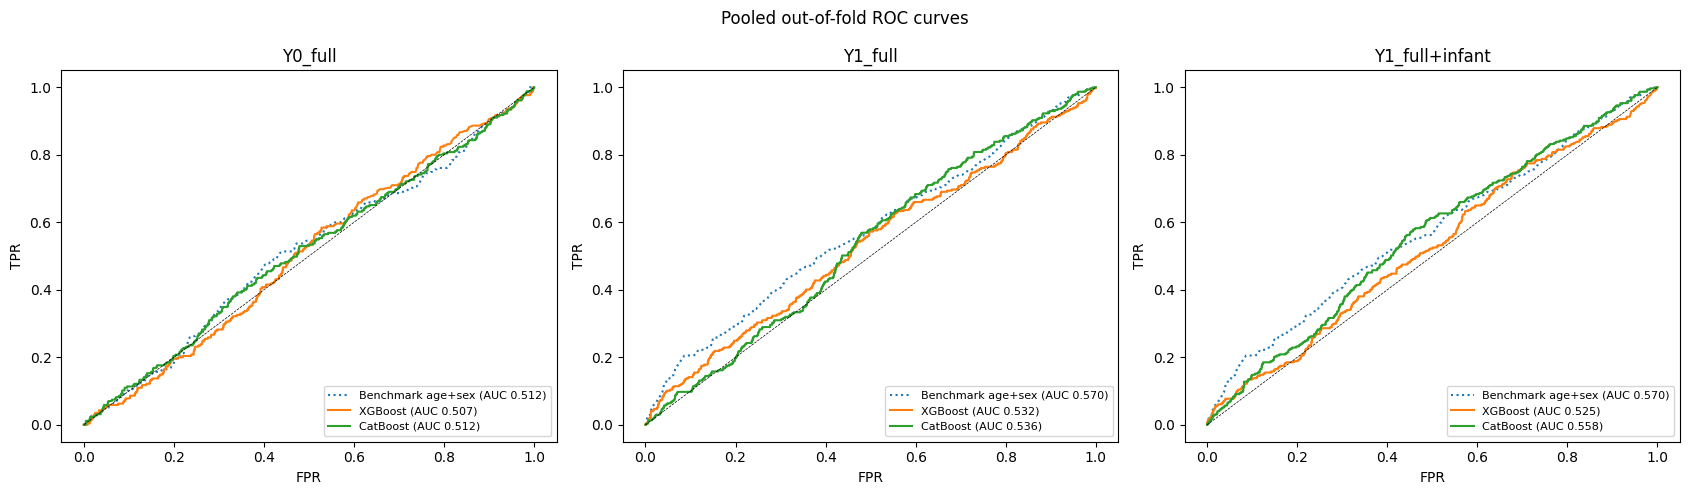

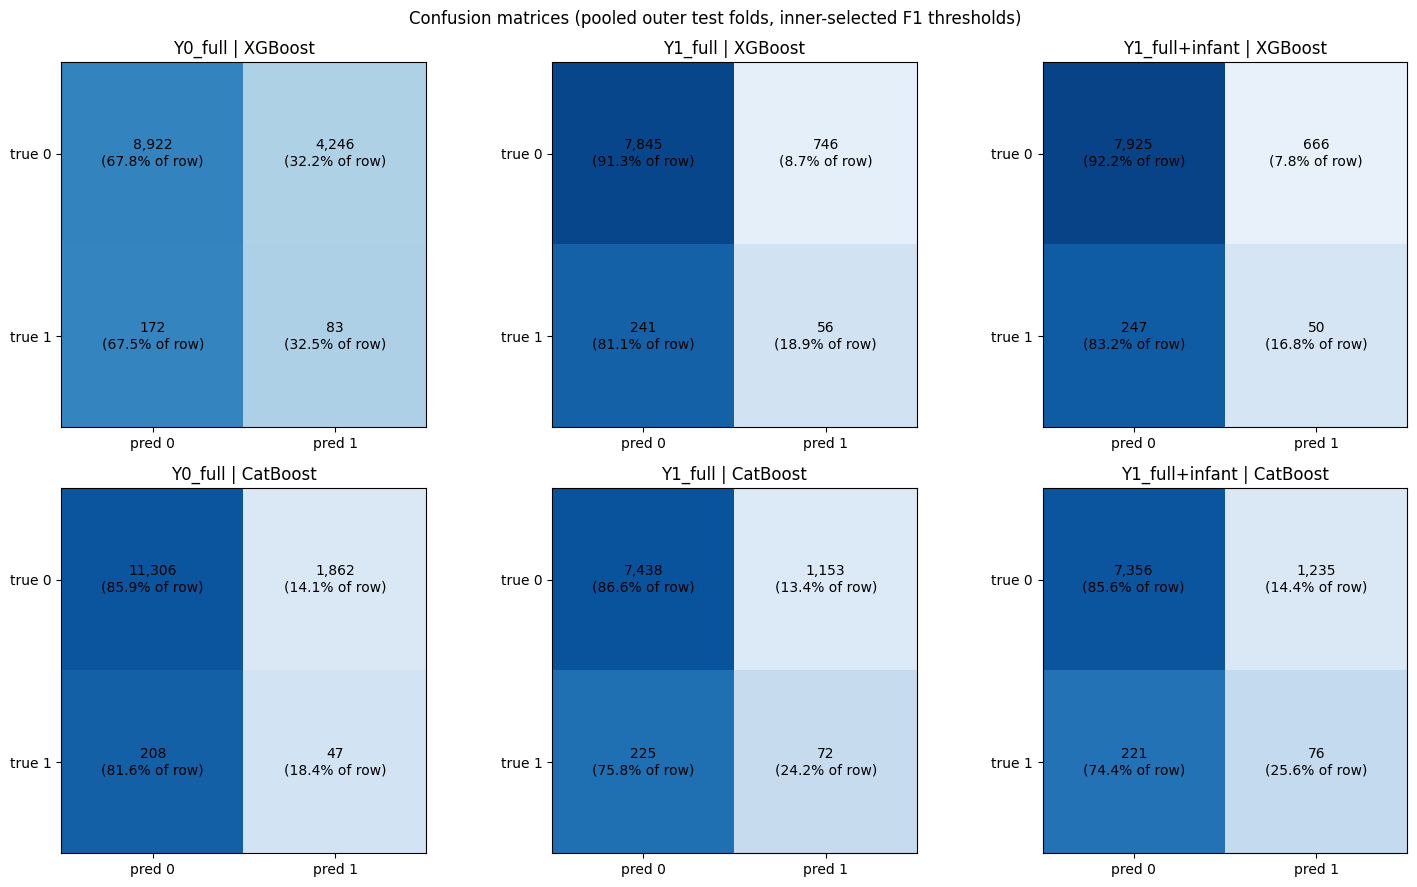

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, key in zip(axes, DATASETS):
    d = DATASETS[key][0]; y = d[TARGET].values
    for name, ls in [('Benchmark age+sex', ':'), ('XGBoost', '-'), ('CatBoost', '-')]:
        fpr, tpr, _ = roc_curve(y, RESULTS[(key, name)]['p'])
        ax.plot(fpr, tpr, ls, label=f"{name} (AUC {RESULTS[(key, name)]['summary']['AUC']:.3f})")
    ax.plot([0, 1], [0, 1], 'k--', lw=.5); ax.set_title(key); ax.set_xlabel('FPR'); ax.set_ylabel('TPR'); ax.legend(loc='lower right', fontsize=8)
plt.suptitle('Pooled out-of-fold ROC curves'); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for r, name in enumerate(['XGBoost', 'CatBoost']):
    for c, key in enumerate(DATASETS):
        y = DATASETS[key][0][TARGET].values; cm = confusion_matrix(y, RESULTS[(key, name)]['pred'], labels=[0, 1])
        ax = axes[r, c]; ax.imshow(cm / cm.sum(1, keepdims=True), cmap='Blues', vmin=0, vmax=1)
        for i in range(2):
            for j in range(2): ax.text(j, i, f'{cm[i,j]:,}\n({cm[i,j]/cm[i].sum():.1%} of row)', ha='center', va='center', fontsize=10)
        ax.set_xticks([0, 1]); ax.set_xticklabels(['pred 0', 'pred 1']); ax.set_yticks([0, 1]); ax.set_yticklabels(['true 0', 'true 1'])
        ax.set_title(f'{key} | {name}')
plt.suptitle('Confusion matrices (pooled outer test folds, inner-selected F1 thresholds)'); plt.tight_layout(); plt.show()

In [10]:
print('Paired AUC gains vs age+sex benchmark and between fea.ture sets (same rows, same folds)')
def gain(a, b): return RESULTS[a]['summary']['AUC'] - RESULTS[b]['summary']['AUC']
rows = []
for name in ['XGBoost', 'CatBoost']:
    rows += [dict(model=name, comparison='Y0 full - benchmark',               dAUC=gain(('Y0_full', name), ('Y0_full', 'Benchmark age+sex'))),
             dict(model=name, comparison='Y1 full - benchmark',               dAUC=gain(('Y1_full', name), ('Y1_full', 'Benchmark age+sex'))),
             dict(model=name, comparison='Y1 full+infant - benchmark',        dAUC=gain(('Y1_full+infant', name), ('Y1_full+infant', 'Benchmark age+sex'))),
             dict(model=name, comparison='Y1 full+infant - Y1 full (infant block value)', dAUC=gain(('Y1_full+infant', name), ('Y1_full', name)))]
display(pd.DataFrame(rows).round(3))
print('Top-8 mean importances per run:')
for k, v in IMPORTANCE.items(): print(k, '->', ', '.join(f'{i} {x:.2f}' for i, x in v.head(8).items()))
print('\nBest hyper-parameters per outer fold saved to outputs/stage1_best_params.csv')

Paired AUC gains vs age+sex benchmark and between fea.ture sets (same rows, same folds)


,model,comparison,dAUC
0,XGBoost,Y0 full - benchmark,-0.005
1,XGBoost,Y1 full - benchmark,-0.038
2,XGBoost,Y1 full+infant - benchmark,-0.045
3,XGBoost,Y1 full+infant - Y1 full (infant block value),-0.007
4,CatBoost,Y0 full - benchmark,-0.001
5,CatBoost,Y1 full - benchmark,-0.034
6,CatBoost,Y1 full+infant - benchmark,-0.012
7,CatBoost,Y1 full+infant - Y1 full (infant block value),0.022


Top-8 mean importances per run:
('Y0_full', 'XGBoost') -> cough_2w 0.11, age_m 0.10, wb4 0.10, female 0.09, edu_level 0.09, division 0.09, diarrhoea_2w 0.06, breathing_2w 0.05
('Y0_full', 'CatBoost') -> age_m 0.14, edu_level 0.10, cough_2w 0.09, female 0.08, diarrhoea_2w 0.07, wb4 0.07, floor_quality 0.07, handwash_water 0.06
('Y1_full', 'XGBoost') -> age_m 0.12, division 0.07, water_cat 0.07, floor_quality 0.07, wb4 0.07, diarrhoea_2w 0.07, edu_level 0.07, female 0.07
('Y1_full', 'CatBoost') -> age_m 0.36, wb4 0.11, edu_level 0.09, water_cat 0.07, floor_quality 0.06, cough_2w 0.05, female 0.05, diarrhoea_2w 0.05
('Y1_full+infant', 'XGBoost') -> age_m 0.10, dds 0.08, birth_size 0.08, anc_cat 0.07, bd9 0.06, division 0.06, diarrhoea_2w 0.06, wb4 0.05
('Y1_full+infant', 'CatBoost') -> age_m 0.19, dds 0.08, bd9 0.07, birth_size 0.07, wb4 0.07, edu_level 0.06, early_bf 0.05, anc_cat 0.05

Best hyper-parameters per outer fold saved to outputs/stage1_best_params.csv


## 5. Reading the results and what comes next

**How to interpret (keep in mind from the project log):**
- With ~255 (young=0) and ~297 (young=1) events, a pooled AUC difference below roughly 0.02-0.03 is within noise; judge gains using the **paired** comparison table and fold-to-fold SD, not a single number.
- F1 / precision are low when prevalence is 2-3% and AUC is ~0.6; recall is traded off against precision by the threshold chosen on inner folds.
- Importances show where signal *might* sit; they are associations, not causes.
- Tuned XGBoost / CatBoost may not beat the age+sex benchmark in `Y0_full` (earlier work found no model reliably above it for ages 2-4).

**Stage 2 (next):** feature engineering (blocks, not all at once; any fitted transform inside training folds only) on top of these same folds.
**Stage 3:** ensembling (XGB + CatBoost + RF + NN + regularised logistic), stacking on out-of-fold predictions saved in `outputs/oof_*.csv`.